# One Δmag envelope or two? Field 860

The pipeline judges a band by σ: the ZTF − PS1 Δmag of the object against a KDE envelope of Δmag versus magnitude,
one envelope per band, built from **all** two-sided bands (`ff.kde_envelopes`), as the pipeline did until 25 November 2026. Point sources are compared in PSF
magnitudes and extended objects in Kron magnitudes (`ff.point_source`, `ff.compared_magnitudes`), but both go into
the same envelope. This notebook shows the two populations, then rebuilds the pipeline's σ step two ways:
**shared** (as now) and **split** (one envelope per morphology), and compares what passes.

Data: the last filter output for field 860 (`Data/fields/000860/filter/objects.parquet`, its envelopes) and the served
candidates (`Data/db_dev_860/sources.parquet`) for the "current candidate" labels. Only `in_both` is involved: the
envelope is built from, and applied to, two-sided bands.

In [1]:
import os, sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from scipy.spatial import cKDTree
from Extracting.utils import sky_xyz
from Source_Analysis import filter_field as ff
B = ff.BANDS; FILT = '../Data/fields/000860/filter'

cols = ['ra', 'dec', 'catalog'] + [f'{b}_{c}' for b in B for c in ('cat', 'ztf_psf', 'ztf_psf_err', 'ztf_kron', 'ztf_kron_err', 'ps1_psf', 'ps1_psf_err', 'ps1_kron', 'ps1_kron_err',
                                                                      'ztf_limit', 'ps1_limit', 'ztf_use_meas', 'ps1_use_forced', 'use_kron', 'sigma')]
src = pd.read_parquet(f'{FILT}/objects.parquet', columns=cols)
src = src[src.catalog == 0].reset_index(drop=True)                                   # in_both: the two-sided objects
for b in B:
    src[f'{b}_use_psf'] = ~src[f'{b}_use_kron'].values                                 # this table predates the `{b}_use_psf` column name
    src[ff.limit_col('ztf', b)], src[ff.limit_col('ps1', b)] = src[f'{b}_ztf_limit'], src[f'{b}_ps1_limit']   # ... and the limit columns' names
src['point_source'] = ff.point_source(src)
src['extended'] = ~src.point_source
cands = pd.read_parquet('../Data/db_dev_860/sources.parquet', columns=['ra', 'dec', 'catalog_tier']); cands = cands[cands.catalog_tier == '0']
d, k = cKDTree(sky_xyz(src.ra.values, src.dec.values)).query(sky_xyz(cands.ra.values, cands.dec.values))
src['candidate'] = False; src.loc[k[d * 206265 < 1], 'candidate'] = True
print(f'in_both objects {len(src):,}; current in_both candidates matched {src.candidate.sum()} of {len(cands)}')

in_both objects 629,142; current in_both candidates matched 335 of 336


## 1. The two populations

`point_source` is one verdict per object: extended when (PSF − Kron − 0.05)/σ, combined over both surveys, exceeds 3
in ≥ 2 measured bands. Point sources then compare PSF magnitudes, extended objects Kron magnitudes.

In [2]:
rows = []
for lab, m in (('point', src.point_source.values), ('extended', src.extended.values)):
    r = {'morphology': lab, 'objects': int(m.sum()), 'fraction': m.mean(), 'current candidates': int((m & src.candidate).sum())}
    for b in B:
        two = m & (src[f'{b}_cat'].values == 0); r[f'{b} two-sided bands'] = int(two.sum())
    rows.append(r)
display(pd.DataFrame(rows).set_index('morphology').round(3))

,objects,fraction,current candidates,g two-sided bands,r two-sided bands,i two-sided bands
morphology,,,,,,
point,515213,0.819,123,324404,495598,504368
extended,113929,0.181,212,92640,106716,104790


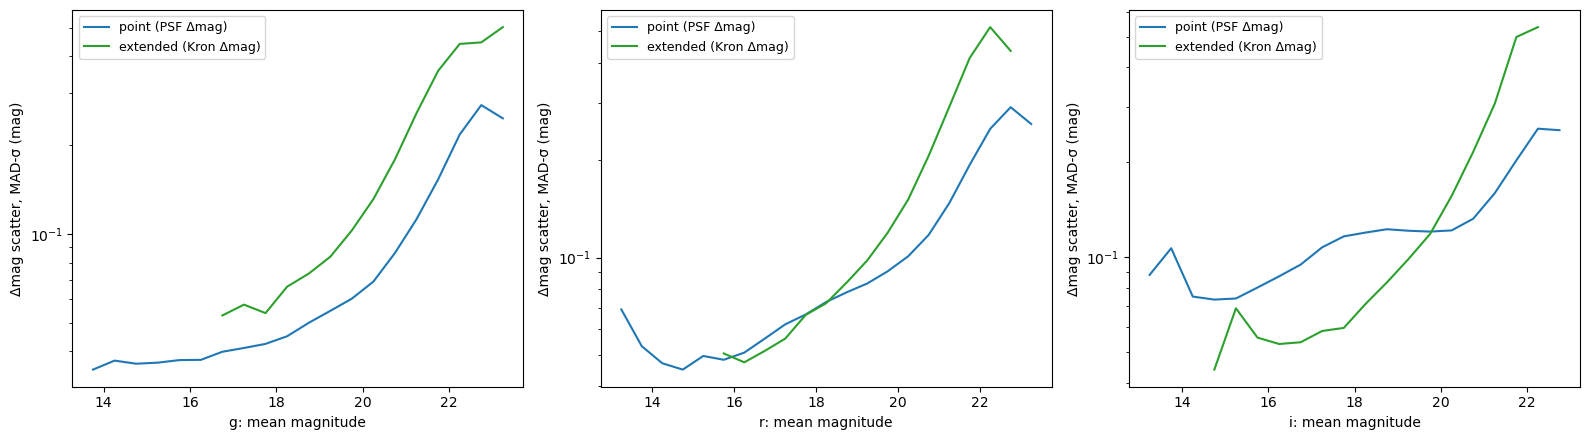

In [3]:
# the magnitudes each population compares, and how much Δmag scatters at each magnitude (1.4826 MAD per 0.5 mag bin)
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, b in zip(axes, B):
    z, _, p, _ = ff.compared_magnitudes(src, b)
    two = (src[f'{b}_cat'].values == 0) & np.isfinite(z) & np.isfinite(p)
    mag, dmag = (z + p) / 2, z - p
    for lab, m, c in (('point (PSF Δmag)', src.point_source.values, 'C0'), ('extended (Kron Δmag)', src.extended.values, 'C2')):
        s = pd.DataFrame({'bin': np.floor(mag[two & m] / 0.5) * 0.5 + 0.25, 'd': dmag[two & m]})
        g = s.groupby('bin').d.agg(lambda x: 1.4826 * np.median(np.abs(x - np.median(x)))); n = s.groupby('bin').size()
        ax.plot(g.index[n > 50], g.values[n > 50], color=c, label=lab)
    ax.set_xlabel(f'{b}: mean magnitude'); ax.set_ylabel('Δmag scatter, MAD-σ (mag)'); ax.set_yscale('log'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

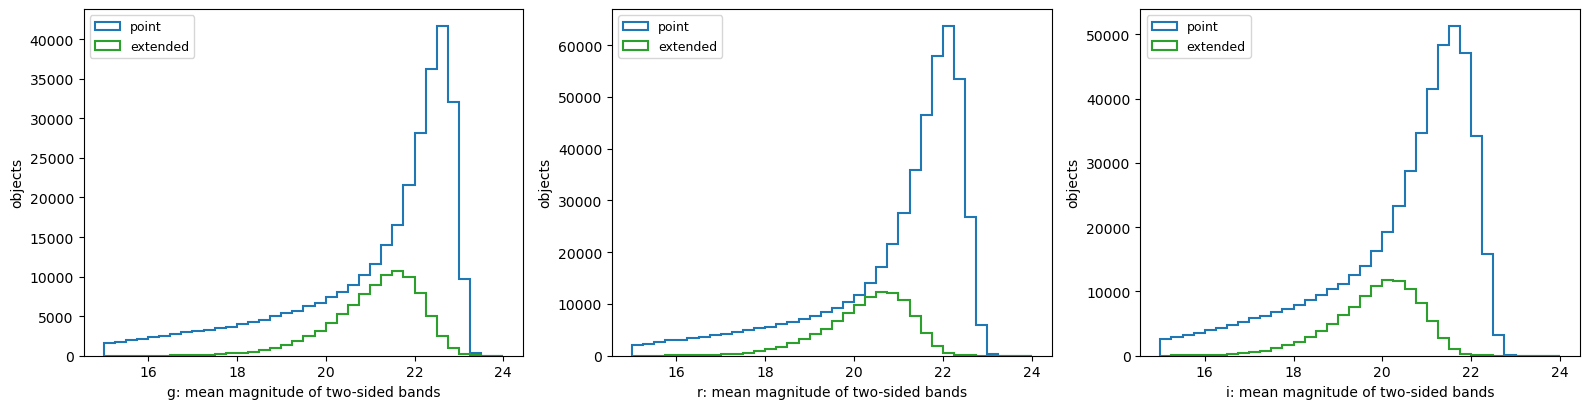

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
for ax, b in zip(axes, B):
    z, _, p, _ = ff.compared_magnitudes(src, b); two = (src[f'{b}_cat'].values == 0) & np.isfinite(z) & np.isfinite(p)
    bins = np.arange(15, 24.1, 0.25)
    for lab, m, c in (('point', src.point_source.values, 'C0'), ('extended', src.extended.values, 'C2')):
        ax.hist(((z + p) / 2)[two & m], bins=bins, histtype='step', color=c, lw=1.5, label=lab)
    ax.set_xlabel(f'{b}: mean magnitude of two-sided bands')
    ax.set_ylabel('objects')
    # ax.set_yscale('log')
    ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

Point sources outnumber extended objects about 4.5 to 1, and they dominate the envelope sample at every magnitude.
Fainter than ~20 mag, the Kron Δmag of extended objects scatters several times more than the PSF Δmag of point sources.

## 2. The σ step as it is now: one shared envelope per band

`ff.annotate_sigma` scores every two-sided band against the saved envelopes; `ff.interesting_checks` is the
|σ| > 3 in ≥ 2 bands, same sign, rule. The stored `{b}_sigma` columns should be reproduced exactly.

In [5]:
env_shared = {b: ff.Envelope_KDE(**{k: v for k, v in np.load(f'{FILT}/envelope_{b}.npz').items()}) for b in B}
def passes(frame):
    checks = ff.interesting_checks(frame); return checks[0][1] & checks[1][1]
shared = ff.annotate_sigma(src, {m: env_shared for m in ff.MORPHOLOGIES})          # the same envelope for both morphologies
print('reproduces the stored sigma:', all(np.allclose(shared[f'{b}_sigma'].fillna(99), src[f'{b}_sigma'].fillna(99), atol=1e-3) for b in B))
pass_shared = passes(shared)
print(f'pass the |σ| rule: {pass_shared.sum()}  (point {(pass_shared & src.point_source).sum()}, extended {(pass_shared & src.extended).sum()})')

reproduces the stored sigma: True
pass the |σ| rule: 676  (point 319, extended 357)


## 3. The σ step with one envelope per morphology

The same pipeline functions, with the envelope sample restricted to one morphology: `ff.clip_envelope_sample`
(outlier clipping, as the pipeline does) → `ff.envelope_tables` → `ff.kde_envelopes`. Each object is then scored
against the envelope of its own morphology. This is now what `ff.filter_prepared` does; the saved envelopes of a new
run are `envelope_{morphology}_{band}.npz`.

In [6]:
def envelopes_for(mask):
    use = {b: mask & (src[f'{b}_cat'].values == 0) for b in B}
    return ff.kde_envelopes(ff.envelope_tables(src, ff.clip_envelope_sample(src, use)))
env_point, env_ext = envelopes_for(src.point_source.values), envelopes_for(src.extended.values)
split = ff.annotate_sigma(src, {'point': env_point, 'extended': env_ext})                    # each object against its own kind
pass_split = passes(split)
print(f'pass the |σ| rule: {pass_split.sum()}  (point {(pass_split & src.point_source).sum()}, extended {(pass_split & src.extended).sum()})')

pass the |σ| rule: 677  (point 555, extended 122)


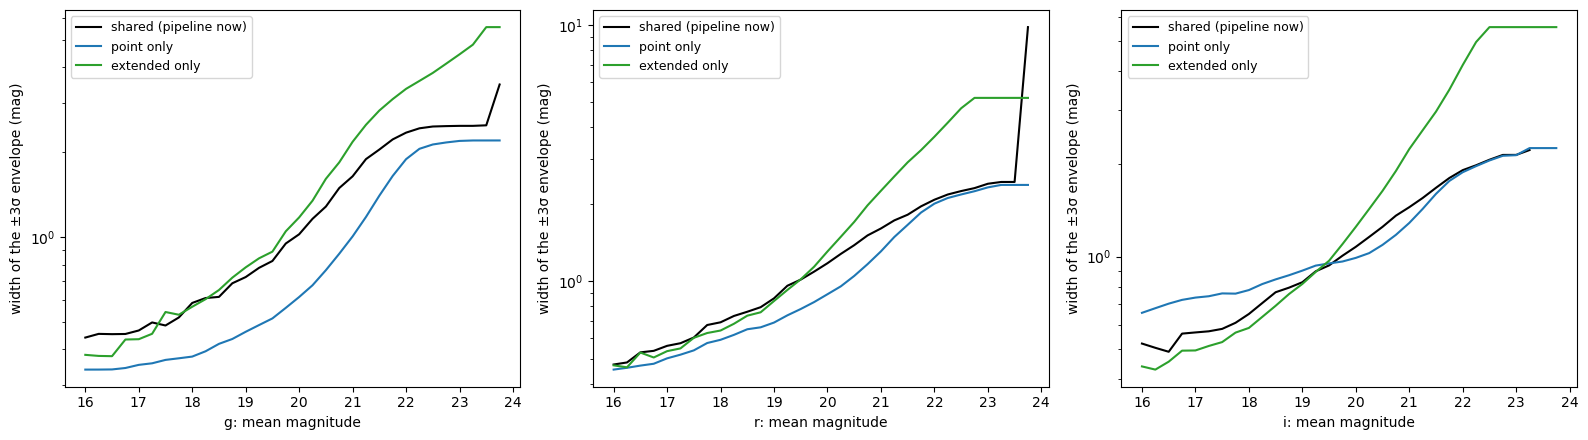

In [7]:
# the envelopes themselves: full width between the ±3σ edges, per magnitude row
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, b in zip(axes, B):
    for env, lab, c in ((env_shared[b], 'shared (pipeline now)', 'k'), (env_point[b], 'point only', 'C0'), (env_ext[b], 'extended only', 'C2')):
        lo, hi = env.get_percentile(env.mag_grid, [0.00135, 0.99865]); ax.plot(env.mag_grid, hi - lo, color=c, label=lab)
    ax.set_xlabel(f'{b}: mean magnitude'); ax.set_ylabel('width of the ±3σ envelope (mag)'); ax.set_yscale('log'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

Each case's envelope over the sample it was built from. The sample is the two-sided bands of that population after
the pipeline's outlier clipping (`ff.clip_envelope_sample`: 5 MAD-σ per 0.5 mag bin, repeated); clipped points are in
red. Lines are the envelope's ±1, 2, 3σ edges (Φ⁻¹ of its Δmag CDF at each magnitude).

shared         629,142 objects scored:  676 pass |σ| > 3 in ≥ 2 bands, same sign; 327 of them current candidates
point only     515,213 objects scored:  555 pass |σ| > 3 in ≥ 2 bands, same sign; 123 of them current candidates
extended only  113,929 objects scored:  122 pass |σ| > 3 in ≥ 2 bands, same sign;  52 of them current candidates


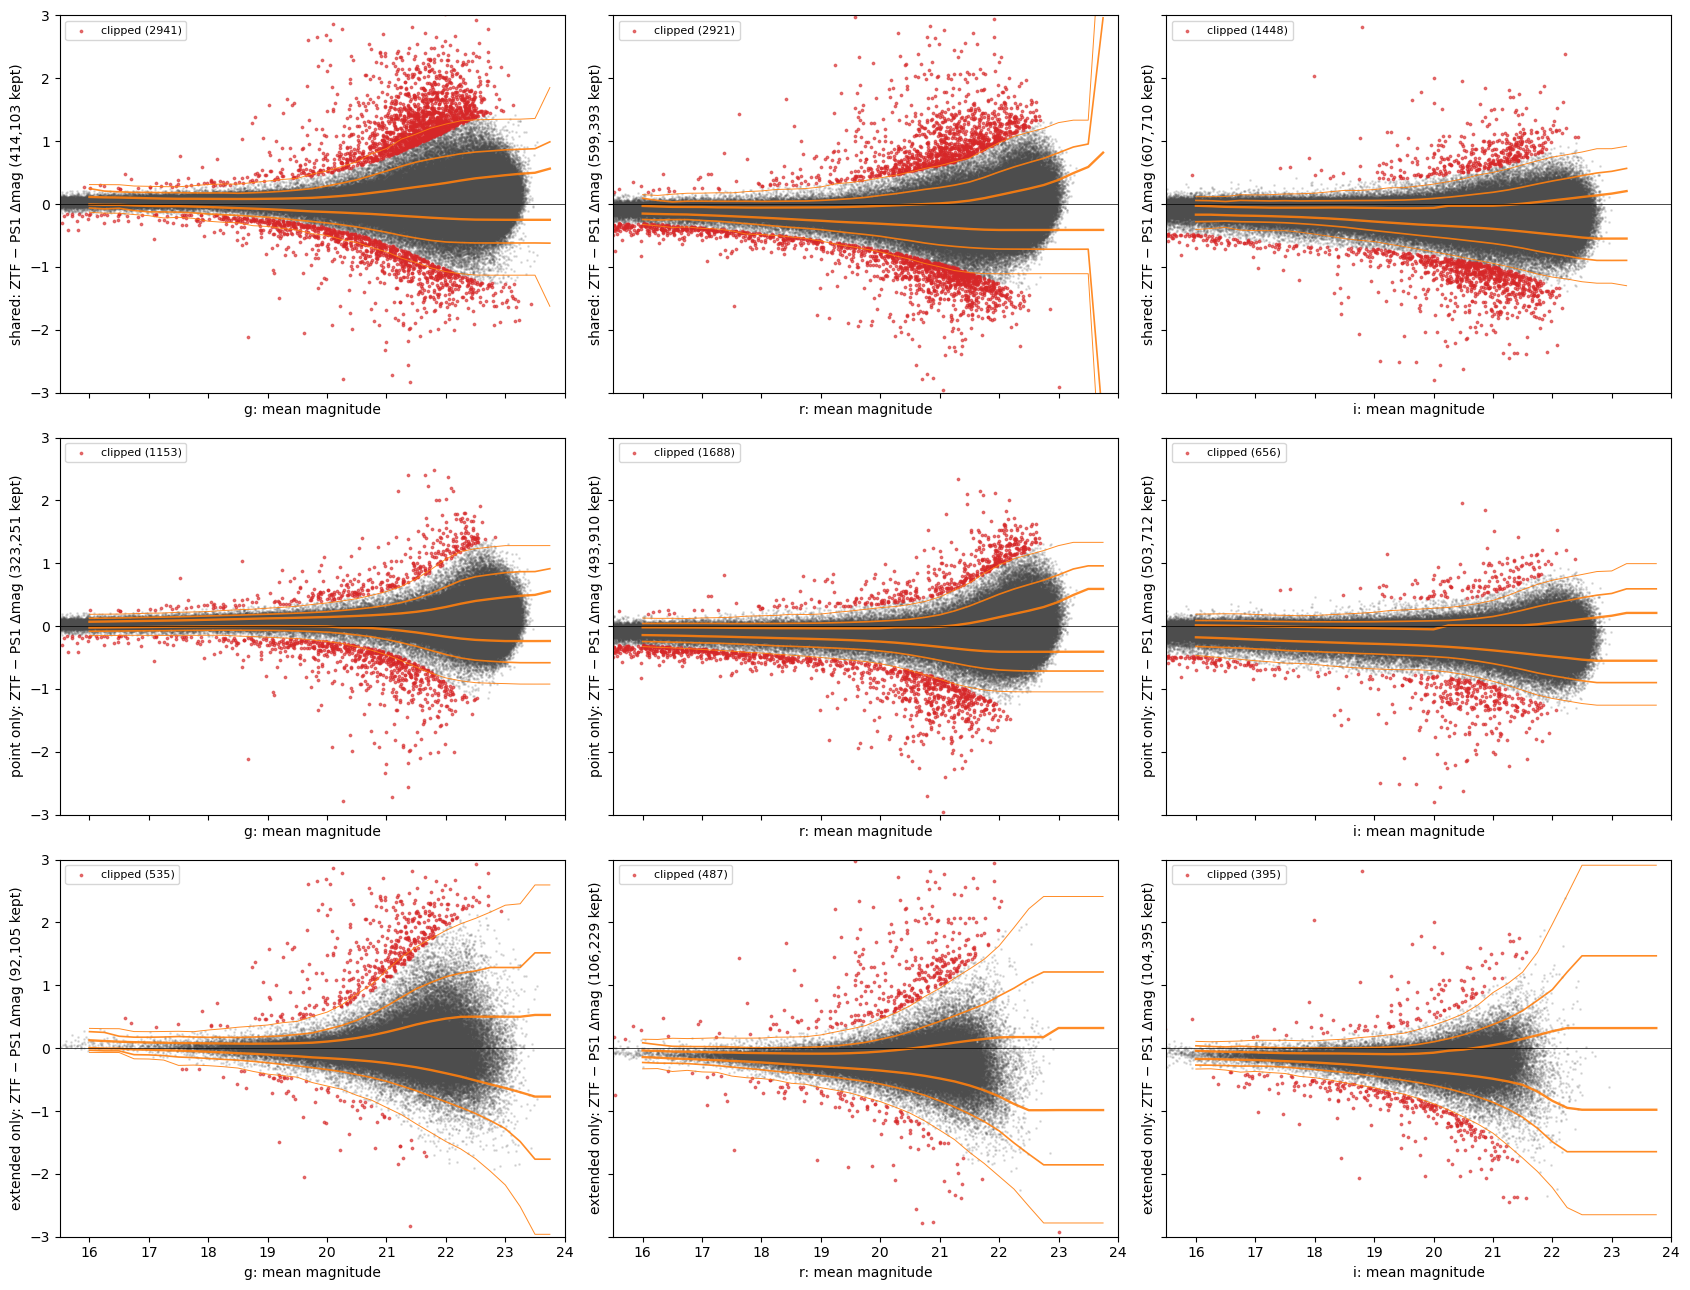

In [8]:
from scipy.stats import norm
cases = (('shared', np.ones(len(src), bool), env_shared), ('point only', src.point_source.values, env_point), ('extended only', src.extended.values, env_ext))
fig, axes = plt.subplots(3, 3, figsize=(17, 13), sharex=True, sharey=True)
for row, (lab, mask, env) in enumerate(cases):
    use = {b: mask & (src[f'{b}_cat'].values == 0) for b in B}; kept = ff.clip_envelope_sample(src, use)
    for col, b in enumerate(B):
        ax = axes[row, col]; z, _, p, _ = ff.compared_magnitudes(src, b)
        two = use[b] & np.isfinite(z) & np.isfinite(p); mag, dmag = (z + p) / 2, z - p
        ax.scatter(mag[kept[b]], dmag[kept[b]], s=1, color='0.3', alpha=0.15, rasterized=True)
        out = two & ~kept[b]; ax.scatter(mag[out], dmag[out], s=3, color='C3', alpha=0.6, rasterized=True, label=f'clipped ({out.sum()})')
        edges = env[b].get_percentile(env[b].mag_grid, [norm.cdf(k) for k in (-3, -2, -1, 1, 2, 3)])
        for e, k in zip(edges, (3, 2, 1, 1, 2, 3)): ax.plot(env[b].mag_grid, e, color='C1', lw=2.2 - 0.5 * k, alpha=0.9)
        ax.set_ylim(-3, 3); ax.set_xlim(15.5, 24); ax.axhline(0, color='k', lw=0.5)
        ax.set_xlabel(f'{b}: mean magnitude'); ax.set_ylabel(f'{lab}: ZTF − PS1 Δmag ({kept[b].sum():,} kept)'); ax.legend(fontsize=8, loc='upper left')
    ok = passes(ff.annotate_sigma(src, {m: env for m in ff.MORPHOLOGIES})) & mask            # this population scored against this envelope
    print(f'{lab:14s} {mask.sum():7,} objects scored: {ok.sum():4d} pass |σ| > 3 in ≥ 2 bands, same sign; {(ok & src.candidate).sum():3d} of them current candidates')
plt.tight_layout(); plt.show()

## 4. What changes

In [9]:
rows = []
for lab, m in (('all in_both', np.ones(len(src), bool)), ('point', src.point_source.values), ('extended', src.extended.values)):
    rows.append({'objects': lab, 'n': int(m.sum()), 'pass now (shared)': int((pass_shared & m).sum()), 'pass with split envelopes': int((pass_split & m).sum()),
                 'lost': int((pass_shared & ~pass_split & m).sum()), 'gained': int((~pass_shared & pass_split & m).sum()),
                 'current candidates': int((src.candidate & m).sum()), 'current candidates still passing': int((src.candidate & pass_split & m).sum())})
display(pd.DataFrame(rows).set_index('objects'))

,n,pass now (shared),pass with split envelopes,lost,gained,current candidates,current candidates still passing
objects,,,,,,,
all in_both,629142,676,677,255,256,335,175
point,515213,319,555,10,246,123,123
extended,113929,357,122,245,10,212,52


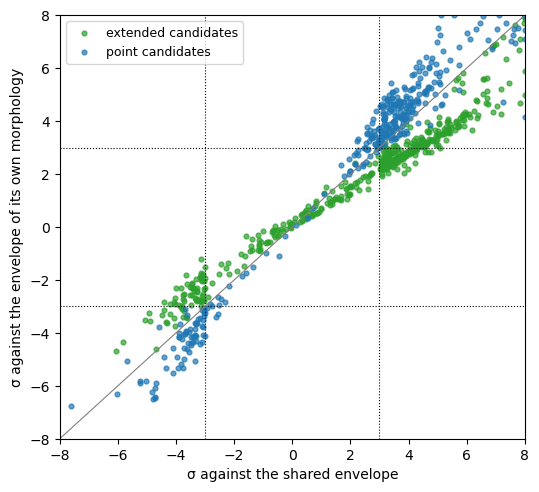

In [10]:
# every current candidate's bands: σ now versus σ against its own morphology's envelope
fig, ax = plt.subplots(figsize=(6, 5.5))
for lab, m, c in (('extended candidates', src.extended.values, 'C2'), ('point candidates', src.point_source.values, 'C0')):
    for b in B:
        w = m & src.candidate.values & (src[f'{b}_cat'].values == 0)
        ax.scatter(shared[f'{b}_sigma'][w], split[f'{b}_sigma'][w], s=12, color=c, alpha=0.7, label=lab if b == 'g' else None)
for v in (-3, 3): ax.axvline(v, color='k', ls=':', lw=0.8); ax.axhline(v, color='k', ls=':', lw=0.8)
ax.plot([-8, 8], [-8, 8], color='0.5', lw=0.8); ax.set_xlim(-8, 8); ax.set_ylim(-8, 8)
ax.set_xlabel('σ against the shared envelope'); ax.set_ylabel('σ against the envelope of its own morphology'); ax.legend(fontsize=9)
plt.show()

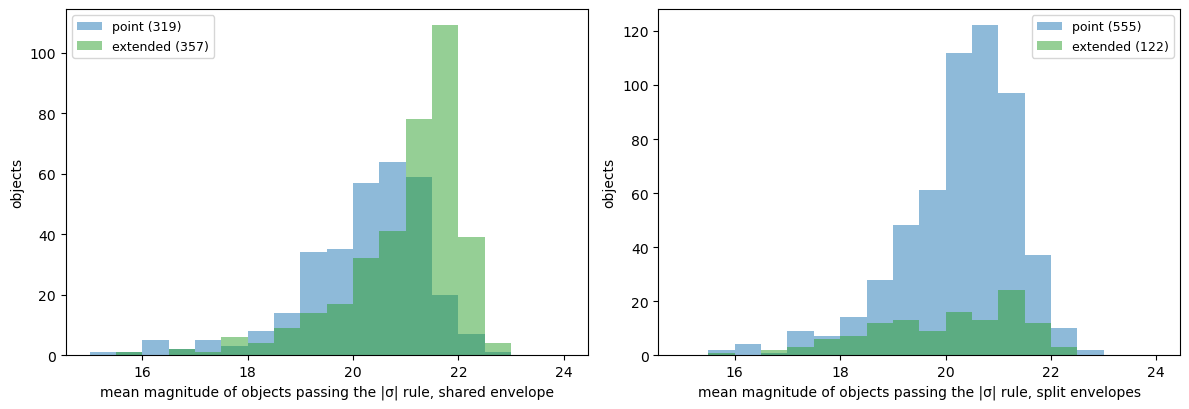

In [11]:
# who passes: morphology mix and magnitudes of the objects passing under each scheme
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
mag = np.nanmean([((ff.compared_magnitudes(src, b)[0] + ff.compared_magnitudes(src, b)[2]) / 2) for b in B], axis=0)
bins = np.arange(15, 24.1, 0.5)
for ax, (lab, p) in zip(axes, (('shared envelope', pass_shared), ('split envelopes', pass_split))):
    ax.hist(mag[p & src.point_source.values], bins=bins, histtype='stepfilled', alpha=0.5, color='C0', label=f'point ({(p & src.point_source).sum()})')
    ax.hist(mag[p & src.extended.values], bins=bins, histtype='stepfilled', alpha=0.5, color='C2', label=f'extended ({(p & src.extended).sum()})')
    ax.set_xlabel(f'mean magnitude of objects passing the |σ| rule, {lab}'); ax.set_ylabel('objects'); ax.legend(fontsize=9)
plt.tight_layout(); plt.show()

**Reading the result.** With the shared envelope, extended objects are ~18% of `in_both` but about half of what passes
the σ rule, because their Kron Δmag is judged against PSF-sized scatter. Against an envelope of their own kind, most of
them fall below 3σ, while point sources, judged against a slightly narrower envelope, gain. The table above gives the
counts; the gained objects have not been through the confident and population cuts, so the real gain in candidates
would be smaller.

Caveats: this is the 18 November filter output (before the Kron-containment, psfChiSq, primary-skycell, spike-orientation
and diffuse-light changes), and the σ rule alone, not the full waterfall. The picture does not depend on either.